# Полный аудит A/B-эксперимента: нарушения протокола

**Уникальный seed:** `1849273` · **Файл:** `exp_data_seed_1849273.csv` · **α = 0.05**

Цель: проверить качество данных, SRM, конфаундинг, временной bias / потенциальный peeking, primary metric, guardrail, множественные сегментные проверки и корректировку. **Главный принцип:** при провале проверок валидности значимый p-value основной метрики не означает, что можно запускать фичу.

Датасет генерируется по схеме задания. Единственное изменение: число пользователей выбирается из диапазона 8500–9999 вместо 1000–9999 для устойчивой оценки редкой метрики ошибок. Повторно запускать генерацию для этого анализа не требуется.

## 1. Загрузка библиотек и данных

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare, chi2_contingency, ttest_ind, ks_2samp, fisher_exact
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf

ALPHA = 0.05
SEED = 1849273
np.random.seed(SEED)
sns.set_theme(style='whitegrid')

# Notebook работает в одной папке с CSV (локально / GitHub / Colab после загрузки обоих файлов).
DATA = Path(f'exp_data_seed_{SEED}.csv')
if not DATA.exists():
    raise FileNotFoundError(f'Положите {DATA.name} рядом с ноутбуком.')
df = pd.read_csv(DATA)
print('Файл:', DATA, '| строк:', len(df), '| столбцов:', df.shape[1])
display(df.head())

Файл: exp_data_seed_1849273.csv | строк: 9127 | столбцов: 7


,user_id,variant,converted,error_flag,weekend,platform,entry_time
0,0,control,0,0,0,1,0.395872
1,1,control,0,0,0,1,0.484212
2,2,control,0,0,0,2,0.980612
3,3,control,0,0,0,1,0.275058
4,4,test,0,0,1,0,0.388432


## 2. Pre-launch: типы, пропуски, дубликаты, диапазоны и единица анализа

Одна строка должна соответствовать одному пользователю. `entry_time` — **доля суток в диапазоне [0,1]**, а не календарная дата и не реальный лог последовательных проверок.

In [2]:
required = ['user_id','variant','converted','error_flag','weekend','platform','entry_time']
assert set(required).issubset(df.columns)
print('Пропущенные значения:'); display(df.isna().sum().rename('missing').to_frame())
print('Повторные user_id:', df.user_id.duplicated().sum(), '; повторные строки:', df.duplicated().sum())
for col in ['converted','error_flag','weekend']:
    assert df[col].isin([0,1]).all(), f'Плохие значения: {col}'
assert df.variant.isin(['control','test']).all()
assert df.platform.isin([0,1,2]).all()
assert df.entry_time.between(0, 1).all()
assert df.user_id.is_unique and not df.isna().any().any()
df['time_delta'] = pd.to_timedelta(df['entry_time'], unit='D')
print('Пример времени сессии:', df.time_delta.iloc[0])
base = df.groupby('variant').agg(n=('user_id','size'),conversion=('converted','mean'),
                                 error_rate=('error_flag','mean'),weekend_share=('weekend','mean'),
                                 mean_entry=('entry_time','mean'))
display(base.style.format({'conversion':'{:.3%}','error_rate':'{:.3%}',
                           'weekend_share':'{:.3%}','mean_entry':'{:.4f}'}))

Пропущенные значения:


,missing
user_id,0
variant,0
converted,0
error_flag,0
weekend,0
platform,0
entry_time,0


Повторные user_id: 0 ; повторные строки: 0
Пример времени сессии: 0 days 09:30:03.340794150


,n,conversion,error_rate,weekend_share,mean_entry
variant,,,,,
control,4726,11.024%,2.179%,9.987%,0.5026
test,4401,14.020%,5.658%,51.693%,0.5028


## 3. SRM: хи-квадрат для ожидаемого 50/50

H₀: назначение пользователей соответствует пропорции 50/50. Отвержение H₀ — тревожный сигнал о некорректной раздаче трафика, не об эффекте фичи.

control=4726, test=4401; χ²=11.573; p=0.00066923353
SRM обнаружен


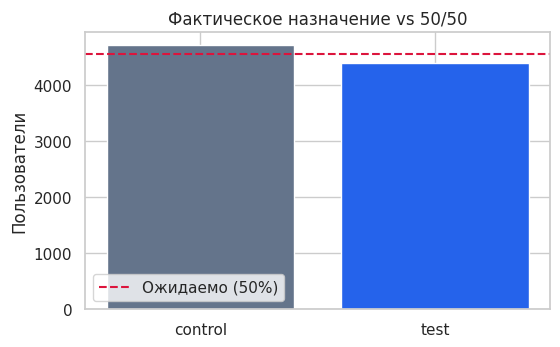

In [3]:
counts = df.variant.value_counts().reindex(['control','test'])
srm_chi2, srm_p = chisquare(counts.values, f_exp=[len(df)/2]*2)
print(f'control={counts["control"]}, test={counts["test"]}; χ²={srm_chi2:.3f}; p={srm_p:.8g}')
print('SRM обнаружен' if srm_p < ALPHA else 'SRM нет')
fig, ax = plt.subplots(figsize=(6,3.6))
ax.bar(['control','test'], counts.values, color=['#64748b','#2563eb'])
ax.axhline(len(df)/2, color='crimson', linestyle='--', label='Ожидаемо (50%)')
ax.set(ylabel='Пользователи',title='Фактическое назначение vs 50/50')
ax.legend(); plt.show()

## 4. Баланс ковариат и confounder

`weekend` — двоичный признак: проверяем χ² независимости и доли по группам. Для `entry_time` — Welch t-test и непараметрический KS. **Нарушенная независимость `weekend` и назначения** делает несмещённую интерпретацию сырой конверсии невозможной.

Баланс weekend: χ²=1882.02, p=0.000e+00
entry_time: Welch p=0.9809; KS p=0.8621


weekend,0,1
variant,,
control,90.01%,9.99%
test,48.31%,51.69%


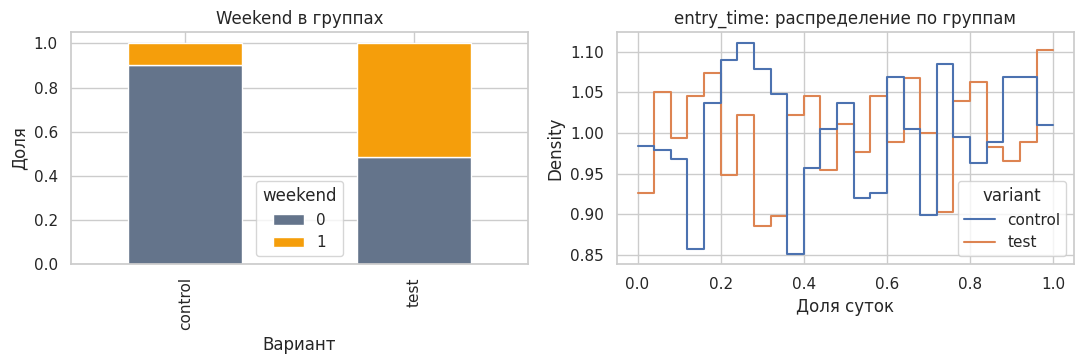

In [4]:
weekend_table = pd.crosstab(df.variant, df.weekend)
weekend_chi2, weekend_p, _, _ = chi2_contingency(weekend_table)
test_time = df.query('variant == "test"').entry_time
control_time = df.query('variant == "control"').entry_time
tw = ttest_ind(test_time, control_time, equal_var=False)
ks = ks_2samp(test_time, control_time)
print(f'Баланс weekend: χ²={weekend_chi2:.2f}, p={weekend_p:.3e}')
print(f'entry_time: Welch p={tw.pvalue:.4f}; KS p={ks.pvalue:.4f}')
display(pd.crosstab(df.variant, df.weekend, normalize='index').style.format('{:.2%}'))
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
weekend_table.div(weekend_table.sum(axis=1),axis=0).plot(kind='bar',stacked=True,ax=axes[0],color=['#64748b','#f59e0b'])
axes[0].set(title='Weekend в группах',ylabel='Доля',xlabel='Вариант');axes[0].legend(title='weekend')
sns.histplot(data=df, x='entry_time',hue='variant',stat='density',common_norm=False,
             element='step',fill=False,bins=25,ax=axes[1])
axes[1].set(title='entry_time: распределение по группам',xlabel='Доля суток')
plt.tight_layout();plt.show()

## 5. Первичная метрика — конверсия (описательно, **без решения о rollout**)

Z-тест двух пропорций; lift = (CR_test / CR_control − 1). 95% ДИ рассчитывается для **абсолютной разницы долей** (test − control) методом Newcombe. Это важно не путать с интервалом относительного lift.

In [5]:
def compare_proportions(data, metric):
    c = data.loc[data.variant.eq('control'), metric]
    t = data.loc[data.variant.eq('test'), metric]
    if len(c)==0 or len(t)==0: raise ValueError('Нет хотя бы одной группы')
    _, p = proportions_ztest([t.sum(),c.sum()],[len(t),len(c)])
    interval = confint_proportions_2indep(int(t.sum()),len(t),int(c.sum()),len(c),
                                         compare='diff',method='newcomb')
    return {'n_control':len(c),'n_test':len(t),'control':c.mean(),'test':t.mean(),
            'rd':t.mean()-c.mean(),'lift':t.mean()/c.mean()-1,
            'ci_low':interval[0],'ci_high':interval[1],'p':p}

primary = compare_proportions(df,'converted')
print(f'CR control={primary["control"]:.3%}, test={primary["test"]:.3%}; '
      f'RD={primary["rd"]:+.3%}; относительный lift={primary["lift"]:+.2%}')
print(f'95% CI абсолютного эффекта=[{primary["ci_low"]:+.3%}, {primary["ci_high"]:+.3%}], '
      f'p={primary["p"]:.6g}')
print('Вывод о запуске здесь запрещён: впереди проверки корректности.')

CR control=11.024%, test=14.020%; RD=+2.995%; относительный lift=+27.17%
95% CI абсолютного эффекта=[+1.637%, +4.359%], p=1.502e-05
Вывод о запуске здесь запрещён: впереди проверки корректности.


## 6. Guardrail: доля ошибок

Двусторонний z-тест + **односторонний точный тест Фишера** для гипотезы H₁: тест увеличивает число ошибок. Если риск ошибок растёт, фичу не следует запускать, даже при росте конверсии.

Ошибка control=2.179%; test=5.658%; Δ=+3.478%
95% CI RD=[+2.688%, +4.294%]
Двусторонний z p=6.512e-18; односторонний Fisher p=2.200e-18


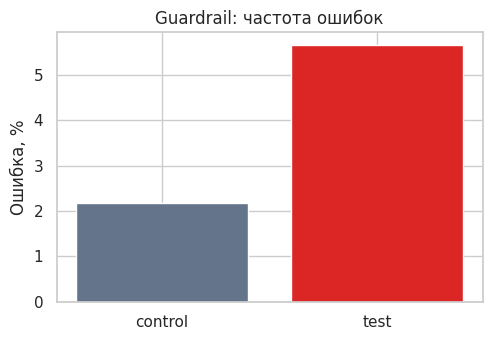

In [6]:
guardrail = compare_proportions(df,'error_flag')
g_tab = pd.crosstab(df.variant,df.error_flag).reindex(index=['test','control'],
                                                      columns=[1,0],fill_value=0)
odds, p_guard_one = fisher_exact(g_tab.to_numpy(),alternative='greater')
print(f'Ошибка control={guardrail["control"]:.3%}; test={guardrail["test"]:.3%}; '
      f'Δ={guardrail["rd"]:+.3%}')
print(f'95% CI RD=[{guardrail["ci_low"]:+.3%}, {guardrail["ci_high"]:+.3%}]')
print(f'Двусторонний z p={guardrail["p"]:.3e}; односторонний Fisher p={p_guard_one:.3e}')
fig,ax=plt.subplots(figsize=(5.5,3.5))
ax.bar(['control','test'],[guardrail['control']*100,guardrail['test']*100],color=['#64748b','#dc2626'])
ax.set(ylabel='Ошибка, %',title='Guardrail: частота ошибок');plt.show()

## 7. Анализ сегментов platform и множественные проверки

Делаем три Z-теста и контролируем FWER методом Holm. Даже поправка не спасает от исследовательского выбора срезов *post hoc*, а сильный сигнал в platform=2 **искусственно записан в генераторе**. Значимость в сегменте нельзя считать доказательством причинного эффекта.

,platform,n_control,n_test,control,test,rd,lift,ci_low,ci_high,p,p_holm,significant_after_holm
0,0,2528,2335,0.110759,0.126338,0.015579,0.140655,-0.002590,0.033862,0.092770,0.185541,False
1,1,1565,1464,0.111182,0.129098,0.017916,0.161143,-0.005240,0.041231,0.129218,0.185541,False
2,2,633,602,0.105845,0.220930,0.115085,1.087296,0.074135,0.156106,0.000000,0.000000,True


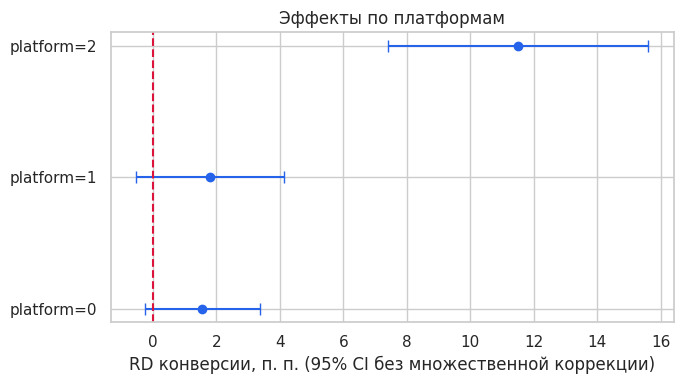

In [7]:
seg=[]
for level, part in df.groupby('platform'):
    r=compare_proportions(part,'converted')
    r['platform']=level
    seg.append(r)
seg=pd.DataFrame(seg).sort_values('platform')
seg['p_holm']=multipletests(seg.p,method='holm')[1]
seg['significant_after_holm']=seg.p_holm<ALPHA
display(seg[['platform','n_control','n_test','control','test','rd','lift','ci_low','ci_high','p','p_holm','significant_after_holm']].round(6))
fig,ax=plt.subplots(figsize=(7,4))
for i,row in enumerate(seg.itertuples()):
    ax.errorbar(row.rd*100,i,xerr=[[ (row.rd-row.ci_low)*100 ],[(row.ci_high-row.rd)*100 ]],
                fmt='o',capsize=4,color='#2563eb')
ax.axvline(0,color='crimson',linestyle='--')
ax.set(yticks=np.arange(len(seg)),yticklabels=[f'platform={x}' for x in seg.platform],
       xlabel='RD конверсии, п. п. (95% CI без множественной коррекции)',
       title='Эффекты по платформам');plt.tight_layout();plt.show()

## 8. Peeking: диагностика временного перекоса и границы вывода

**Важная ловушка генератора:** первоначальное `variant = where(entry_time > 0.4, ...)` ниже *перезаписывается*. Последующие изменения назначения зависят от `weekend`, но не от `entry_time`. Поэтому time bias может отсутствовать. Проверки формы распределения и логистическая регрессия полезны, однако **по одному финальному CSV нельзя доказать peeking / раннюю остановку**: нужны логи промежуточных анализов и протокол stopping rule.

Разница среднего entry_time (test−control): +0.000145
Welch p=0.9809, KS p=0.8621, логит p=0.9809


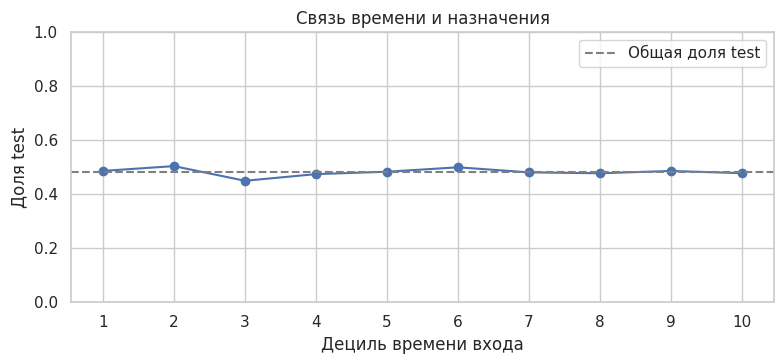

Peeking не установлен. Для аудита нужны timestamp проверок, результаты промежуточных тестов, заранее выбранная длительность и правило остановки.


In [8]:
df['is_test']=(df.variant=='test').astype(int)
fit_time=smf.glm('is_test ~ entry_time',data=df,family=sm.families.Binomial()).fit()
print(f'Разница среднего entry_time (test−control): {test_time.mean()-control_time.mean():+.6f}')
print(f'Welch p={tw.pvalue:.4f}, KS p={ks.pvalue:.4f}, '
      f'логит p={fit_time.pvalues["entry_time"]:.4f}')
df['time_decile']=pd.cut(df.entry_time, bins=np.linspace(0,1,11),include_lowest=True)
share=df.groupby('time_decile',observed=True).is_test.mean()
fig,ax=plt.subplots(figsize=(8,3.8))
ax.plot(np.arange(1,11),share.values,marker='o');ax.axhline(df.is_test.mean(),ls='--',color='gray',label='Общая доля test')
ax.set(xticks=np.arange(1,11),ylim=(0,1),xlabel='Дециль времени входа',ylabel='Доля test',
       title='Связь времени и назначения');ax.legend();plt.tight_layout();plt.show()
print('Peeking не установлен. Для аудита нужны timestamp проверок, результаты промежуточных тестов, '+
      'заранее выбранная длительность и правило остановки.')

## 9. Исправление: стратифицированная стандартизация + регрессия

Корректируем измеренные `weekend` и `platform` через общую структуру совместных страт (g-computation / direct standardization). Разницу оцениваем как сумму Σ w_s × (CR_test,s − CR_control,s). 95% ДИ — приближённый normal/Wald, рассчитанный из биномиальных дисперсий в стратах. Проверяем перекрытие всех страт. Дополнительно приводим GLM с робастной ковариационной матрицей. **Ни один из этих методов не восстанавливает корректность распределения и не устраняет guardrail.**

,weekend,platform,weight,control_n,test_n,cell_effect
0,0,0,0.37701,2280,1161,-0.01008
1,0,1,0.22987,1408,690,-0.01674
2,0,2,0.09214,566,275,0.16849
3,1,0,0.15580,248,1174,-0.00774
4,1,1,0.10201,157,774,-0.01168
5,1,2,0.04317,67,327,0.05797


Сырая RD=+2.995%, скорректированная RD=+0.798%
95% CI скорректированной RD=[-0.782%, +2.379%]
Логистическая регрессия с HC3: OR=1.086; 95% CI OR=(0.941, 1.253), p=0.2569


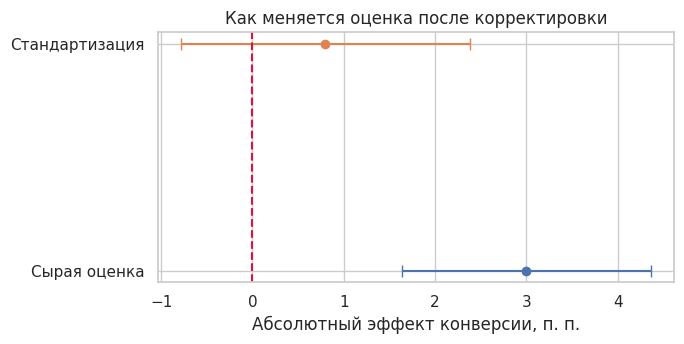

In [9]:
weights=df.groupby(['weekend','platform']).size()/len(df)
weighted_rd=0.0
weighted_var=0.0
rows=[]
for (w,p),weight in weights.items():
    cell=df[(df.weekend==w)&(df.platform==p)]
    c=cell[cell.variant=='control'].converted
    t=cell[cell.variant=='test'].converted
    assert min(len(c),len(t))>0, f'Нет перекрытия: {(w,p)}'
    weighted_rd+=weight*(t.mean()-c.mean())
    weighted_var+=weight**2*(c.mean()*(1-c.mean())/len(c)+t.mean()*(1-t.mean())/len(t))
    rows.append({'weekend':w,'platform':p,'weight':weight,'control_n':len(c),'test_n':len(t),
                 'cell_effect':t.mean()-c.mean()})
display(pd.DataFrame(rows).round(5))
weighted_se=np.sqrt(weighted_var)
weighted_ci=(weighted_rd-1.96*weighted_se,weighted_rd+1.96*weighted_se)
print(f'Сырая RD={primary["rd"]:+.3%}, скорректированная RD={weighted_rd:+.3%}')
print(f'95% CI скорректированной RD=[{weighted_ci[0]:+.3%}, {weighted_ci[1]:+.3%}]')
reg=smf.glm('converted ~ C(variant) + weekend + C(platform)',data=df,
            family=sm.families.Binomial()).fit(cov_type='HC3')
name='C(variant)[T.test]'
print(f'Логистическая регрессия с HC3: OR={np.exp(reg.params[name]):.3f}; '
      f'95% CI OR={tuple(np.exp(reg.conf_int().loc[name]).round(3))}, p={reg.pvalues[name]:.4f}')
fig,ax=plt.subplots(figsize=(7,3.6))
for i,(rd,ci) in enumerate([(primary['rd'],(primary['ci_low'],primary['ci_high'])),
                            (weighted_rd,weighted_ci)]):
    ax.errorbar(rd*100,i,xerr=[[(rd-ci[0])*100],[(ci[1]-rd)*100]],fmt='o',capsize=4)
ax.axvline(0,ls='--',c='crimson');ax.set(yticks=[0,1],yticklabels=['Сырая оценка','Стандартизация'],
       xlabel='Абсолютный эффект конверсии, п. п.',title='Как меняется оценка после корректировки')
plt.tight_layout();plt.show()

## 10. Финальный продуктовый вывод и план исправления

In [10]:
blockers=[]
if srm_p<ALPHA: blockers.append('SRM')
if weekend_p<ALPHA: blockers.append('небаланс weekend')
if guardrail['rd']>0 and p_guard_one<ALPHA: blockers.append('guardrail ухудшен')
if tw.pvalue<ALPHA or ks.pvalue<ALPHA: blockers.append('временной дисбаланс (не доказанный peeking)')
print('Блокирующие нарушения:', ', '.join(blockers) if blockers else 'нет')
print(f'Сырая конверсия: {primary["control"]:.2%} vs {primary["test"]:.2%}; p={primary["p"]:.2e}')
print(f'После корректировки: {weighted_rd:+.2%} (95% CI {weighted_ci[0]:+.2%} ... {weighted_ci[1]:+.2%})')
print(f'Guardrail: {guardrail["control"]:.2%} -> {guardrail["test"]:.2%}; Fisher p={p_guard_one:.2e}')
print('РЕШЕНИЕ: НЕ ROLLOUT. Повторить эксперимент с исправленным дизайном.')

Блокирующие нарушения: SRM, небаланс weekend, guardrail ухудшен
Сырая конверсия: 11.02% vs 14.02%; p=1.50e-05
После корректировки: +0.80% (95% CI -0.78% ... +2.38%)
Guardrail: 2.18% -> 5.66%; Fisher p=2.20e-18
РЕШЕНИЕ: НЕ ROLLOUT. Повторить эксперимент с исправленным дизайном.


### Интерпретация и рекомендации

1. **Pre-launch.** Пропусков и повторных user_id нет. Это не гарантирует корректности рандомизации.
2. **SRM.** Отвергается ожидаемое 50/50; необходимо проверить assignment и маршрутизацию трафика до чтения эффекта.
3. **Confounder.** `weekend` встречается в тесте многократно чаще, а выходной влияет на вероятность конверсии. Сырая разница конверсий смешивает эффект фичи с эффектом состава групп.
4. **Первичная метрика.** Номинально значима, но этот результат нельзя интерпретировать как причинный из-за нарушенного протокола и сегментного артефакта.
5. **Guardrail.** В тесте ошибки возникают значительно чаще, это самостоятельная причина остановки.
6. **Сегменты.** В `platform=2` есть значимый после Holm всплеск, но в генераторе он **внедрён искусственно**. Необходим аудит логики событий, аномальных источников и предварительная регистрация сегментных гипотез. Интервалы на диаграмме сегментов не скорректированы за множественность.
7. **Peeking.** По итоговым данным не подтверждается. Временное назначение в исходном коде перезаписывается; отсутствие временного дисбаланса **не доказывает отсутствие** многократных просмотров результатов. Отделить time bias от реального optional stopping можно только по логам и заранее зарегистрированным правилам.
8. **Корректировка.** Стандартизация показывает чувствительность оценки к составу групп, но **не «спасает»** протокол: она не лечит SRM, селекцию, guardrail и искусственную подмену конверсий в platform 2. `weekend` является наблюдаемым исходным фактором, но не настоящей непрерывной CUPED-ковариатой.
9. **Новый запуск.** Закрепить единицу рандомизации `user_id`, использовать устойчивое 50/50 хеширование и sticky assignment; провести A/A и автоматические SRM/ковариатные проверки, зафиксировать primary и guardrail, мощность/горизонт теста и правило остановки (или заранее определить sequential design с alpha spending). Предварительно указать семью тестов и поправку на множественность; проверить instrumentation по платформам, мониторить ошибки и заранее задать safety stop. Только после этого повторно оценивать rollout.

**Решение:** **не запускать** текущую фичу на всех пользователях; **повторить тест после исправлений**. Это не вывод об отсутствии истинного эффекта — это вывод о недостоверности текущего свидетельства в пользу запуска.
